## Proyecto Final - Caso B
## ¿Qué pedidos llegarán tarde? — Predicción de retrasos en TransAndes

## **Analítica de Datos I · Universidad Icesi ·**
## **Integrantes: Martin Lozano, Juliana Garrido y Maria Paula Rubio**



### **Fase 1: Compresion del negocio**

**1. CONTEXTO Y PROBLEMA:**

TransAndes es una distribuidora que despacha pedidos desde cuatro centros de distribución ubicados en Cali, Bogotá, Medellín y Barranquilla. Para realizar sus entregas, utiliza diferentes tipos de vehículos, como motos, furgones y camiones, que transportan los pedidos hacia zonas urbanas, periurbanas y rurales.

La empresa establece una ventana de entrega para cada cliente; sin embargo, durante el año 2025, cerca de tres de cada diez pedidos llegaron después del tiempo prometido. Esta situación representa un problema para la operación, ya que los retrasos pueden generar quejas, penalidades por incumplimiento de los acuerdos con clientes empresariales e incluso la pérdida de clientes de hogar, afectando la satisfacción del cliente y por tanto los ingresos de la empresa.

Actualmente, TransAndes identifica los retrasos una vez que estos ocurren, lo que limita su capacidad de tomar medidas preventivas. Por esta razón, el objetivo del proyecto es desarrollar un modelo de clasificación que permita predecir, en el momento del despacho, si un pedido tiene riesgo de llegar tarde. Para ello, se utilizará únicamente la información disponible , con el propósito de generar alertas tempranas que permitan al equipo de operaciones tomar decisiones oportunas y prevenir posibles incumplimientos en las entregas.

**2. QUE ES UN ACIERTO Y QUE ES UN ERROR:**

Bajo este contexto, un acierto es cuando la predicción del modelo es igual a lo que realmente ocurre con el pedido; en este caso hay dos tipos de aciertos. El verdadero positivo, que aplica cuando el modelo anticipa que el pedido va a llegar tarde y efectivamente llega tarde, lo que permite que la empresa tenga oportunidad de reaccionar antes de que el retraso ocurra. O el segundo acierto, que es verdadero negativo, donde el modelo indica que el pedido va a llegar a tiempo y en efecto eso es lo que ocurre; por lo tanto, no se gastan recursos de más. 


Ahora bien, un error es cuando la predicción del modelo no coincide con la realidad de lo que ocurre con el pedido y también hay dos tipos de errores. El primero es el falso negativo, donde el modelo predice que el pedido va a llegar a tiempo, pero en lugar de eso llega tarde. En este caso, la empresa no va a tener tiempo o margen para poder actuar. Y finalmente está el falso positivo, que aplica cuando el modelo predice que el pedido va a llegar tarde, pero llega a tiempo, lo que conlleva a que la empresa tome medidas que no eran necesarias y gaste recursos. 

**3. CUAL TIPO DE ERROR ES MAS COSTOSO PARA LA EMPRESA:**

En el caso de la empresa TransAndes, un falso negativo es más costoso que un falso positivo, debido a que si el modelo predice que el pedido va a llegar a tiempo y en realidad llega tarde, la empresa no va a tener un margen de tiempo para poder reaccionar, por lo que el retraso puede terminar significando una queja, una posible penalidad con un cliente o, en el mayor de los casos, el riesgo directo de perder clientes. Si bien un falso positivo implica tomar una medida preventiva que va a terminar siendo innecesaria, como asignar a un conductor más especializado o avisar al cliente, al final estas resultan siendo costos operativos que son moderados. 

Por esta razón, la métrica prioritaria debe ser el recall de la clase positiva (pedidos con entrega tardía), ya que indica qué proporción de los pedidos que realmente llegaron tarde logra identificar correctamente el modelo. Sin embargo, como un recall alto podría conseguirse clasificando demasiados pedidos como riesgosos, también se deben considerar la precisión y el F1-score, que permiten evaluar el equilibrio entre la detección de retrasos y la cantidad de falsas alarmas.

Finalmente, el accuracy no debe utilizarse como criterio principal de evaluación, ya que puede dar una impresión engañosa del desempeño del modelo cuando existe un desequilibrio entre las clases. En este caso, como los pedidos que llegan a tiempo son más frecuentes que los que llegan tarde, el modelo podría obtener un buen porcentaje de aciertos al predecir principalmente entregas a tiempo, sin lograr identificar los pedidos que realmente presentan retrasos.



# Fase 2 · Comprensión de los datos (EDA)

 Primero vamos a hacer el diagnóstico de la base cruda (dimensiones, tipos, nulos, balance de clases). Los análisis univariado y bivariado se van a  hacer después de corregir duplicados, categorías y valores imposibles (Fase 3, pasos 3.1–3.3), pero antes de imputar los nulos, así las gráficas no se distorsionan con los valores ultra raros , y tampoco con valores rellenados a nuestro criterio.

## 2.1 Diagnóstico de la base cruda

### Carga de las librerias a utilizar y de la base de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
print("✅ Librerías cargadas correctamente")

✅ Librerías cargadas correctamente


In [2]:
df = pd.read_csv("logistica_entregas.csv")
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (8035, 17)


,id_pedido,fecha_despacho,dia_semana,centro_distribucion,zona_destino,tipo_vehiculo,distancia_km,peso_kg,num_paradas,hora_salida,clima,experiencia_conductor_anios,edad_vehiculo_anios,tipo_cliente,prioridad,valor_pedido_COP,entrega_tardia
0,P-04180,2025-10-24,Viernes,Cali,Rural,Furgón,58.9,115.5,10.0,19.0,Lluvia,5.7,9.0,Empresa,Normal,193700.0,Sí
1,P-00296,2025-11-19,Miércoles,Bogotá,Urbana,Furgón,25.7,264.3,NaN,17.0,Lluvia,3.2,4.0,NaN,Normal,361300.0,Sí
2,P-02789,2025-02-23,Domingo,Medellín,Urbana,Moto,18.6,NaN,7.0,20.0,Soleado,NaN,5.0,Hogar,Express,170600.0,No
3,P-01284,2025-01-21,Martes,Bogotá,Urbana,Moto,5.1,9.2,1.0,6.0,Soleado,10.2,5.0,Empresa,Normal,622400.0,No
4,P-05152,2025-07-12,Sábado,Bogotá,Urbana,Furgón,14.2,260.5,1.0,5.0,Lluvia,6.5,15.0,Hogar,Normal,406500.0,No


La base de datos tiene 17 columnas y 8035 filas.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8035 entries, 0 to 8034
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id_pedido                    8035 non-null   str    
 1   fecha_despacho               8035 non-null   str    
 2   dia_semana                   8035 non-null   str    
 3   centro_distribucion          8035 non-null   str    
 4   zona_destino                 8035 non-null   str    
 5   tipo_vehiculo                8035 non-null   str    
 6   distancia_km                 7633 non-null   float64
 7   peso_kg                      7391 non-null   float64
 8   num_paradas                  7550 non-null   float64
 9   hora_salida                  7713 non-null   float64
 10  clima                        7311 non-null   str    
 11  experiencia_conductor_anios  7149 non-null   float64
 12  edad_vehiculo_anios          7475 non-null   float64
 13  tipo_cliente                 

In [4]:
df.describe().round(2)

,distancia_km,peso_kg,num_paradas,hora_salida,experiencia_conductor_anios,edad_vehiculo_anios,valor_pedido_COP
count,7633.00,7391.00,7550.00,7713.00,7149.00,7475.00,7634.00
mean,34.21,370.06,6.56,12.53,4.98,7.35,301474.63
std,36.32,616.10,3.44,4.59,3.49,4.58,296305.39
min,-144.10,0.00,0.00,5.00,0.10,0.00,11300.00
25%,11.30,10.45,4.00,9.00,2.40,3.00,125800.00
50%,19.40,143.30,6.00,12.00,4.20,7.00,216000.00
75%,43.50,328.05,9.00,16.00,6.60,11.00,374875.00
max,299.00,6341.20,23.00,30.00,30.00,15.00,5752400.00


La base tiene 8.035 filas × 17 columnas. En describe() se ven señales de datos "sucios", distancia_km tiene un mínimo negativo (-144), hora_salida llega a 30 (las horas válidas van de 0 a 23), peso_kg y num_paradas tienen mínimo 0. Además, info() muestra que 9 columnas tienen datos faltantes.

### Nulos por columna

In [5]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2)
})
nulos = nulos[nulos["nulos"] > 0].sort_values("porcentaje", ascending=False)
print(nulos)

print(sum(nulos["nulos"]), "valores nulos en total")

                             nulos  porcentaje
experiencia_conductor_anios    886       11.03
clima                          724        9.01
peso_kg                        644        8.01
edad_vehiculo_anios            560        6.97
num_paradas                    485        6.04
distancia_km                   402        5.00
valor_pedido_COP               401        4.99
hora_salida                    322        4.01
tipo_cliente                   243        3.02
4667 valores nulos en total


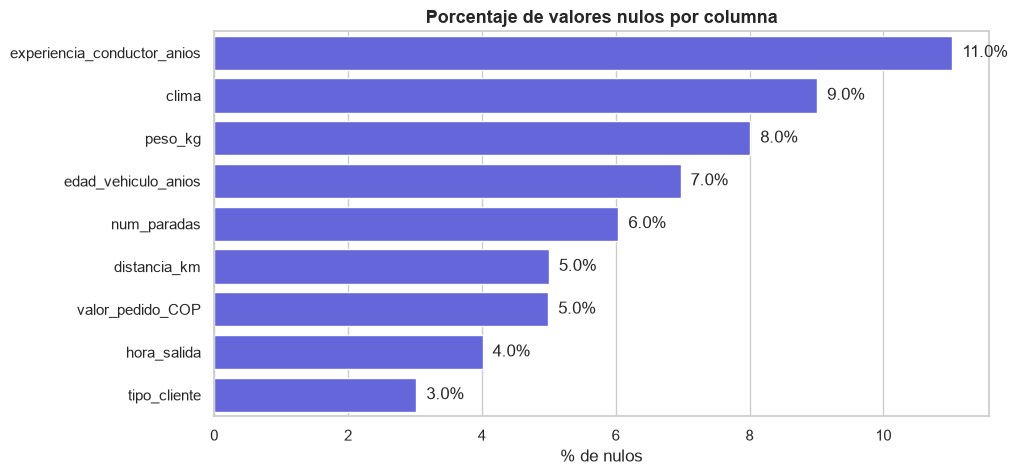

In [7]:
plt.figure(figsize=(10, 5))
sns.barplot(x=nulos["porcentaje"], y=nulos.index, color="#5353EE")
for i, v in enumerate(nulos["porcentaje"]):
    plt.text(v + 0.15, i, f"{v:.1f}%", va="center")
plt.title("Porcentaje de valores nulos por columna")
plt.xlabel("% de nulos")
plt.ylabel("")
plt.show()

**Interpretación:** Hay nulos en 9 de las 17 columnas, en proporciones distintas. La más afectada es experiencia_conductor_anios (11 %), seguida de clima (9 %), peso_kg (8 %) y edad_vehiculo_anios (7 %). Ninguna columna supera el 11 %.

### Balance de clases de la variable objetivo

entrega_tardia
No    5513
Sí    2522
Name: count, dtype: int64
entrega_tardia
No    68.6
Sí    31.4
Name: proportion, dtype: float64


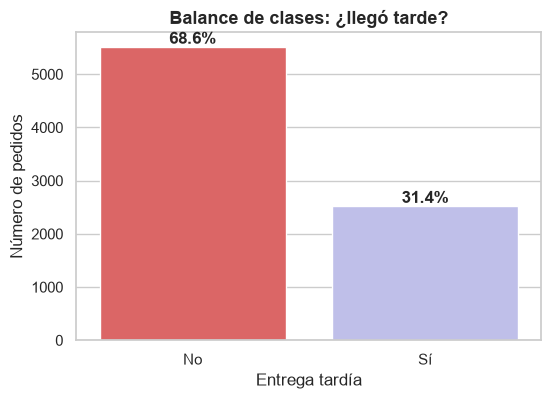

In [6]:
conteo = df["entrega_tardia"].value_counts()
print(conteo)
print((df["entrega_tardia"].value_counts(normalize=True) * 100).round(1))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="entrega_tardia", order=["No", "Sí"],
              palette=["#B8B8F0", "#EE5353"], hue="entrega_tardia", legend=False)
plt.title("Balance de clases: ¿llegó tarde?")
plt.xlabel("Entrega tardía")
plt.ylabel("Número de pedidos")
for i, c in enumerate(["No", "Sí"]):
    plt.text(i, conteo[c] + 60, f"{conteo[c]/len(df)*100:.1f}%", ha="center", fontweight="bold")
plt.show()

**Interpretación:** El 31,4 % de los pedidos llegó tarde y el 68,6 % a tiempo, por tanto las clases no están balanceadas. 

Consecuencias: 

(1) Usaremos stratify=y para que se converve la misma proporción entre pedidos a tiempo y tardíos en train y test.

(2) El accuracy puede engañar (un modelo "siempre a tiempo" tendría ≈ 69 %), como se mencionó previamente.

(3) Probaremos class_weight="balanced", pues le da mayor importancia a la clase menos frecuente (pedidos tardíos) para evitar que el modelo se concentre únicamente en predecir la clase mayoritaria.

### Problemas de calidad detectados (antes de limpiar)

In [7]:
print("Filas completamente duplicadas:", df.duplicated().sum())
print("IDs de pedido duplicados     :", df["id_pedido"].duplicated().sum())
print()
for col in ["dia_semana", "centro_distribucion", "zona_destino", "tipo_vehiculo",
            "clima", "tipo_cliente", "prioridad", "entrega_tardia"]:
    print(f"{col}:", df[col].value_counts(dropna=False).to_dict(), "\n")

Filas completamente duplicadas: 35
IDs de pedido duplicados     : 35

dia_semana: {'Lunes': 1206, 'Miércoles': 1173, 'Domingo': 1150, 'Jueves': 1140, 'Viernes': 1135, 'Martes': 1120, 'Sábado': 1111} 

centro_distribucion: {'Cali': 2688, 'Bogotá': 2412, 'Medellín': 1486, 'Barranquilla': 1208, 'CALI ': 47, 'barranquilla': 45, 'Medellin': 40, 'BOGOTÁ': 38, 'Bogota': 37, 'cali': 34} 

zona_destino: {'Urbana': 4379, 'Periurbana': 2231, 'Rural': 1425} 

tipo_vehiculo: {'Furgón': 3487, 'Moto': 2813, 'Camión': 1585, 'furgon': 48, 'MOTO': 39, 'Camion': 32, 'Furgon': 31} 

clima: {'Soleado': 2891, 'Nublado': 2068, 'Lluvia': 1592, 'Lluvia fuerte': 760, nan: 724} 

tipo_cliente: {'Hogar': 3541, 'Empresa': 2312, 'Tienda': 1939, nan: 243} 

prioridad: {'Normal': 6056, 'Express': 1979} 

entrega_tardia: {'No': 5513, 'Sí': 2522} 



In [8]:
print("distancia_km < 0     :", (df["distancia_km"] < 0).sum())
print("peso_kg == 0         :", (df["peso_kg"] == 0).sum())
print("num_paradas == 0     :", (df["num_paradas"] == 0).sum())
print("hora_salida fuera 0-23:", (df["hora_salida"] > 23).sum(), sorted(df.loc[df["hora_salida"] > 23, "hora_salida"].unique()))
print("valor_pedido <= 0    :", (df["valor_pedido_COP"] <= 0).sum())
print("experiencia < 0      :", (df["experiencia_conductor_anios"] < 0).sum())
print("edad_vehiculo < 0    :", (df["edad_vehiculo_anios"] < 0).sum())

distancia_km < 0     : 20
peso_kg == 0         : 15
num_paradas == 0     : 59
hora_salida fuera 0-23: 10 [np.float64(25.0), np.float64(30.0)]
valor_pedido <= 0    : 0
experiencia < 0      : 0
edad_vehiculo < 0    : 0


**Resumen del diagnóstico**

| Problema | Hallazgo |
|---|---|
| Duplicados | 35 filas completamente duplicadas (mismo id_pedido) |
| Categorías mal escritas | centro_distribucion: CALI , cali, BOGOTÁ, Bogota, Medellin, barranquilla. tipo_vehiculo ; MOTO, furgon, Furgon, Camion |
| Valores imposibles | 20 distancias negativas ; 15 pesos = 0 kg ; 59 pedidos con 0 paradas ; 10 horas de salida > 23 (25 y 30) |
| Nulos | 9 columnas, entre 3 % y 11 % |

---
# Fase 3 · Preparación de los datos


## 3.1 Copia de seguridad y duplicados

In [9]:
df_limpio = df.copy()

filas_antes = len(df_limpio)
df_limpio = df_limpio.drop_duplicates().copy()
print("Filas antes:", filas_antes, "| después:", len(df_limpio), "| eliminadas:", filas_antes - len(df_limpio))
print("IDs duplicados restantes:", df_limpio["id_pedido"].duplicated().sum())

Filas antes: 8035 | después: 8000 | eliminadas: 35
IDs duplicados restantes: 0


**Decisión:** eliminamos las 35 filas duplicadas. Un mismo pedido contado dos veces le daría doble peso en el train o podría aparecer a la vez en train y test.

## 3.2 Estandarizar categorías


In [10]:
def normalizar(texto):
    """minúsculas, sin espacios extremos y sin tildes (para poder comparar)"""
    if pd.isna(texto):
        return texto
    t = unicodedata.normalize("NFKD", str(texto).strip().lower())
    return t.encode("ascii", "ignore").decode()

mapa_centro = {"cali": "Cali", "bogota": "Bogotá", "medellin": "Medellín", "barranquilla": "Barranquilla"}
mapa_vehiculo = {"moto": "Moto", "furgon": "Furgón", "camion": "Camión"}

df_limpio["centro_distribucion"] = df_limpio["centro_distribucion"].map(normalizar).map(mapa_centro)
df_limpio["tipo_vehiculo"] = df_limpio["tipo_vehiculo"].map(normalizar).map(mapa_vehiculo)

print(df_limpio["centro_distribucion"].value_counts(dropna=False).to_dict())
print(df_limpio["tipo_vehiculo"].value_counts(dropna=False).to_dict())

{'Cali': 2761, 'Bogotá': 2475, 'Medellín': 1517, 'Barranquilla': 1247}
{'Furgón': 3547, 'Moto': 2841, 'Camión': 1612}


Se pasó a minúsculas, se quitarón espacios y tildes para obtener una sola versión de los niveles de las columnas a corregir (normalizar). Una vez realizado esto, se puede reemplazar los niveles por el nombre único dado el diccionario.


In [11]:
df_limpio["fecha_despacho"] = pd.to_datetime(df_limpio["fecha_despacho"], errors="coerce")
df_limpio["mes"] = df_limpio["fecha_despacho"].dt.month
print("Fechas no válidas:", df_limpio["fecha_despacho"].isna().sum())
df_limpio["entrega_tardia_bin"] = (df_limpio["entrega_tardia"] == "Sí").astype(int)

Fechas no válidas: 0


**Resultado:** quedan exactamente 4 centros de distribución y 3 tipos de vehículo. Se pasó fecha_despacho a  tipo datetime (sin fechas inválidas), se creó mes para analizar si los retrasos tienen alguna relación con el mes del despacho, y  se creó entrega_tardia_bin (1 = Sí, 0 = No), que es la versión numérica binaria del objetivo.


## 3.3 Valores imposibles
No se reemplazan dichos valores arbitrariamente. Cada caso recibe una regla distinta según qué pudo haber pasado.

| Variable | Problema | Decisión y justificación |
|---|---|---|
| distancia_km negativa (20) | Error de signo | Valor absoluto. La magnitud es coherente con la zona (ejemplo: -144 en zona rural, donde la mediana es 86 km), por lo que solo se equivocó el signo. |
| peso_kg = 0 (15) | Un pedido no pesa 0 kg | Se convierte a NaN y se imputa luego. |
| num_paradas = 0 (59) | Una ruta de entrega tiene al menos 1 parada | Se convierte a NaN y se imputa luego. |
| hora_salida > 23 (10) | La hora solo va de 0 a 23 | Se convierte a NaN. |

In [12]:
n_dist = (df_limpio["distancia_km"] < 0).sum()
n_peso = (df_limpio["peso_kg"] == 0).sum()
n_par = (df_limpio["num_paradas"] == 0).sum()
n_hora = (df_limpio["hora_salida"] > 23).sum()

# 1) Distancia negativa: error de signo -> valor absoluto (la magnitud es coherente con la zona)
df_limpio.loc[df_limpio["distancia_km"] < 0, "distancia_km"] = df_limpio["distancia_km"].abs()
# 2) Peso 0, paradas 0 y hora > 23: no tienen sentido físico -> NaN (se tratan como faltantes)
df_limpio.loc[df_limpio["peso_kg"] == 0, "peso_kg"] = np.nan
df_limpio.loc[df_limpio["num_paradas"] == 0, "num_paradas"] = np.nan
df_limpio.loc[df_limpio["hora_salida"] > 23, "hora_salida"] = np.nan

print(f"distancias negativas corregidas con abs(): {n_dist}")
print(f"pesos = 0 convertidos a NaN               : {n_peso}")
print(f"paradas = 0 convertidas a NaN             : {n_par}")
print(f"horas > 23 convertidas a NaN              : {n_hora}")
print("distancia mínima ahora:", df_limpio["distancia_km"].min())

distancias negativas corregidas con abs(): 20
pesos = 0 convertidos a NaN               : 15
paradas = 0 convertidas a NaN             : 59
horas > 23 convertidas a NaN              : 10
distancia mínima ahora: 2.9


### Valores extremos "válidos" (método IQR)
Un valor extremo no siempre es un error. Un camión puede pesar 6 toneladas y una ruta rural puede tener 299 km. Revisamos con IQR, pero no vamos a  eliminar a ciegas:

In [13]:
def contar_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"limite_inf": round(inf, 1), "limite_sup": round(sup, 1),
                      "atipicos": int(((serie < inf) | (serie > sup)).sum()),
                      "maximo": serie.max()})

cols_num = ["distancia_km", "peso_kg", "num_paradas", "experiencia_conductor_anios",
            "edad_vehiculo_anios", "valor_pedido_COP"]
pd.DataFrame({c: contar_iqr(df_limpio[c].dropna()) for c in cols_num}).T

,limite_inf,limite_sup,atipicos,maximo
distancia_km,-37.1,92.0,631.0,299.0
peso_kg,-466.5,805.5,1169.0,6341.2
num_paradas,-3.5,16.5,39.0,23.0
experiencia_conductor_anios,-3.9,12.9,264.0,30.0
edad_vehiculo_anios,-9.0,23.0,0.0,15.0
valor_pedido_COP,-247737.5,748362.5,466.0,5752400.0


In [14]:
print(df_limpio.groupby("tipo_vehiculo")["peso_kg"].describe().round(0))
print()
print(df_limpio.groupby("zona_destino")["distancia_km"].median().round(1))

                count    mean    std  min    25%     50%     75%     max
tipo_vehiculo                                                           
Camión         1477.0  1364.0  758.0  6.0  840.0  1207.0  1680.0  6341.0
Furgón         3260.0   206.0  132.0  3.0  129.0   181.0   252.0  2167.0
Moto           2608.0    14.0   71.0  2.0    6.0     8.0    12.0  1915.0

zona_destino
Periurbana    34.4
Rural         86.0
Urbana        11.8
Name: distancia_km, dtype: float64


**Decisión:** conservamos los atípicos de peso_kg, distancia_km y valor_pedido_COP. El peso depende del vehículo (moto ≈ 8 kg, furgón ≈ 181 kg, camión ≈ 1.200 kg), por lo que un peso de 6.000 kg en un camión es normal; y la distancia depende de la zona (urbana ≈ 12 km, rural ≈ 86 km). Son datos reales de la operación, y justamente las rutas largas y pesadas son las que más nos interesa estudiar.


## Fase 2 (continuación) · EDA sobre la base corregida

### Análisis univariado — variables numéricas

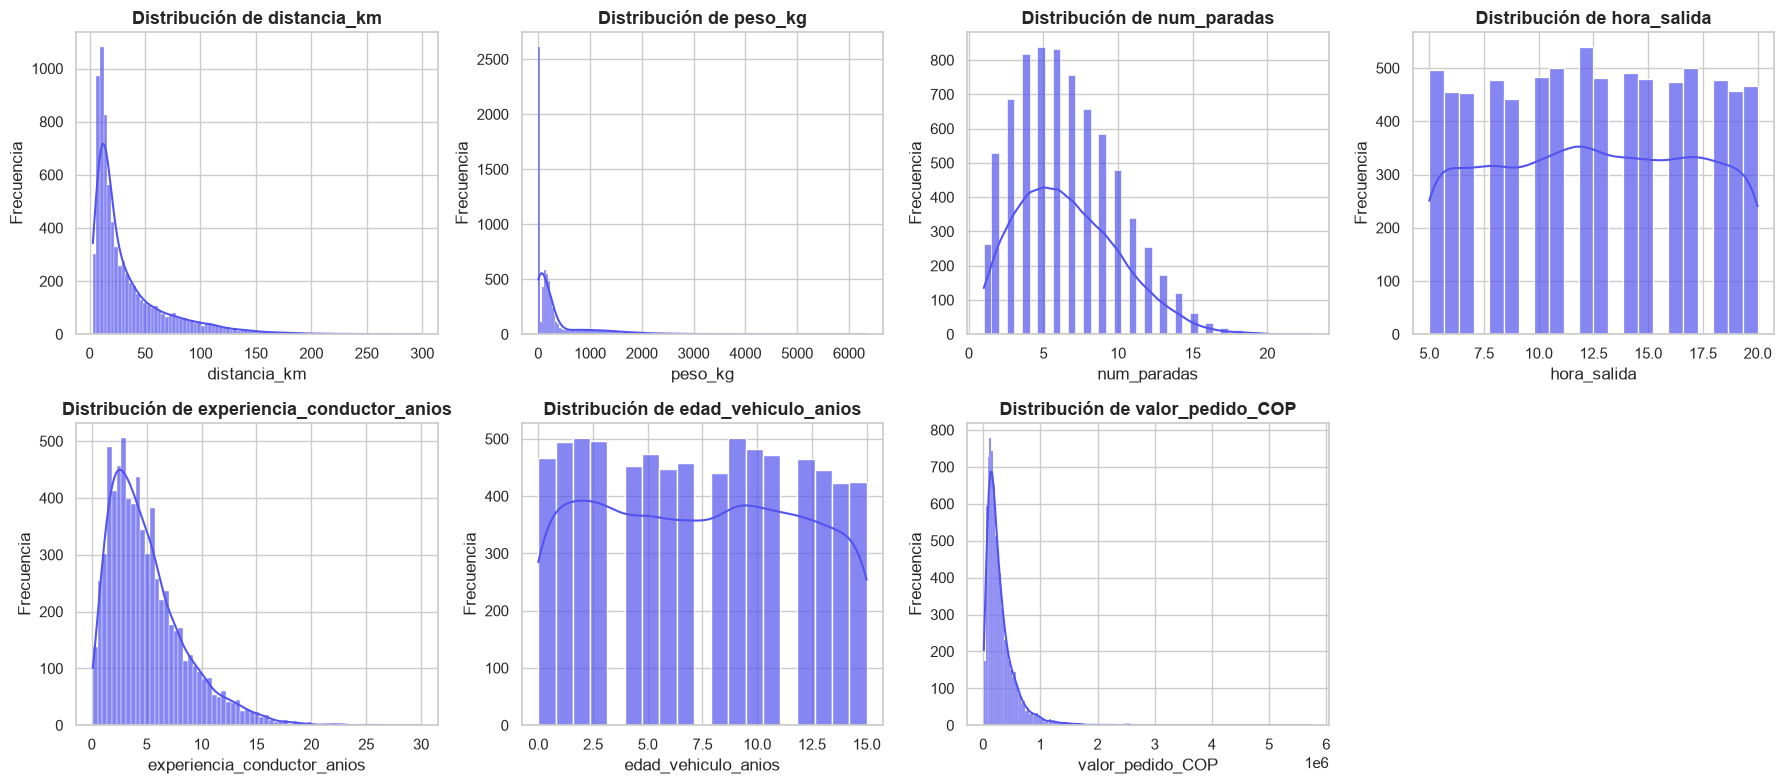

                                 Media   Mediana        Std  Asimetría
distancia_km                     34.39      19.5      36.00       2.27
peso_kg                         371.06     143.7     617.05       2.83
num_paradas                       6.61       6.0       3.41       0.56
hora_salida                      12.51      12.0       4.57      -0.01
experiencia_conductor_anios       4.98       4.2       3.48       1.36
edad_vehiculo_anios               7.36       7.0       4.58       0.03
valor_pedido_COP             301391.92  215900.0  296078.41       4.41


In [15]:
vars_num = ["distancia_km", "peso_kg", "num_paradas", "hora_salida",
            "experiencia_conductor_anios", "edad_vehiculo_anios", "valor_pedido_COP"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, var in enumerate(vars_num):
    sns.histplot(data=df_limpio, x=var, kde=True, ax=axes[i], color="#5353EE", alpha=0.7)
    axes[i].set_title(f"Distribución de {var}")
    axes[i].set_ylabel("Frecuencia")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

resumen = pd.DataFrame({
    "Media": df_limpio[vars_num].mean().round(2),
    "Mediana": df_limpio[vars_num].median().round(2),
    "Std": df_limpio[vars_num].std().round(2),
    "Asimetría": df_limpio[vars_num].skew().round(2),
})
print(resumen)

**Interpretación:**
- distancia_km, peso_kg, valor_pedido_COP y experiencia_conductor_anios tienen asimetría positiva (cola larga a la derecha; la media supera a la mediana). Es la mezcla común en logística, es decir muchos pedidos pequeños y cercanos, y pocos grandes y lejanos. Para estas variables la mediana describe mejor el caso típico, y por eso la usaremos para imputar los datos nulos.

- hora_salida es casi uniforme entre las 5 y las 20 h (asimetría ≈ 0), entonces no hay una hora dominante.

- edad_vehiculo_anios es aproximadamente uniforme entre 0 y 15 años y num_paradas se concentra entre 3 y 9.

### Análisis univariado — variables categóricas

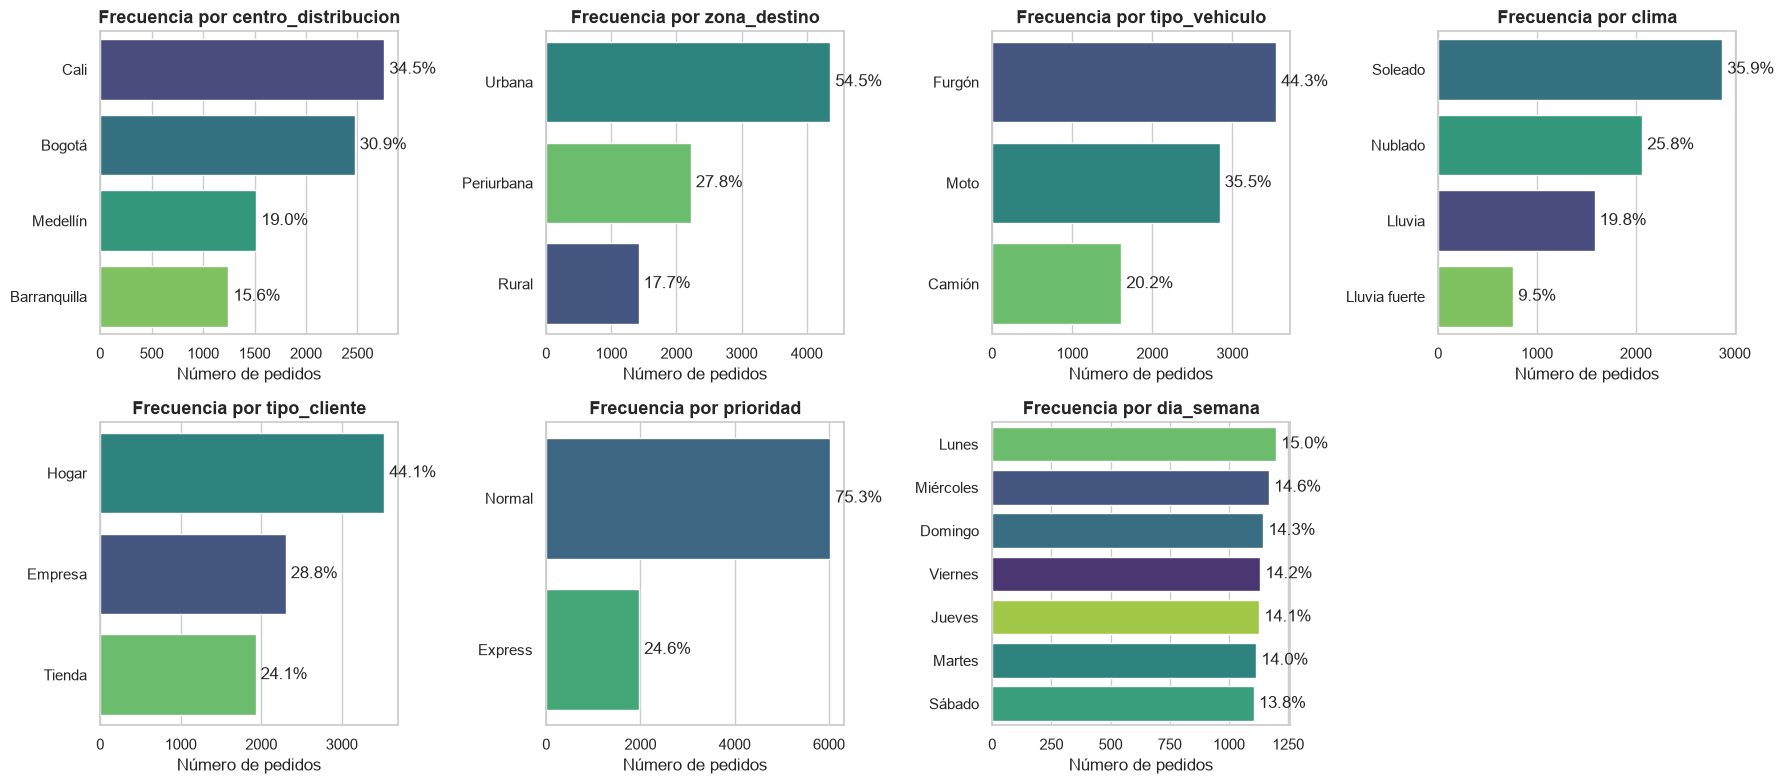

In [16]:
vars_cat = ["centro_distribucion", "zona_destino", "tipo_vehiculo", "clima",
            "tipo_cliente", "prioridad", "dia_semana"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for ax, var in zip(axes, vars_cat):
    orden = df_limpio[var].value_counts().index
    sns.countplot(data=df_limpio, y=var, order=orden, ax=ax, palette="viridis", hue=var, legend=False)
    ax.set_title(f"Frecuencia por {var}")
    ax.set_xlabel("Número de pedidos")
    ax.set_ylabel("")
    for barra in ax.patches:
        porcentaje = barra.get_width() / len(df_limpio) * 100
        ax.text(barra.get_width(), barra.get_y() + barra.get_height()/2,
                f" {porcentaje:.1f}%", va="center")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

**Interpretación:** Cali (34.5 %) y Bogotá (30.9 %) concentran los despachos. La mayoría de pedidos son a zona urbana (54.5 %) y con prioridad Normal (75.3 %). Los furgones son el vehículo más usado. El número de pedidos es casi parejo entre los días de la semana.

### Análisis bivariado — ¿cómo se relaciona cada variable con llegar tarde?


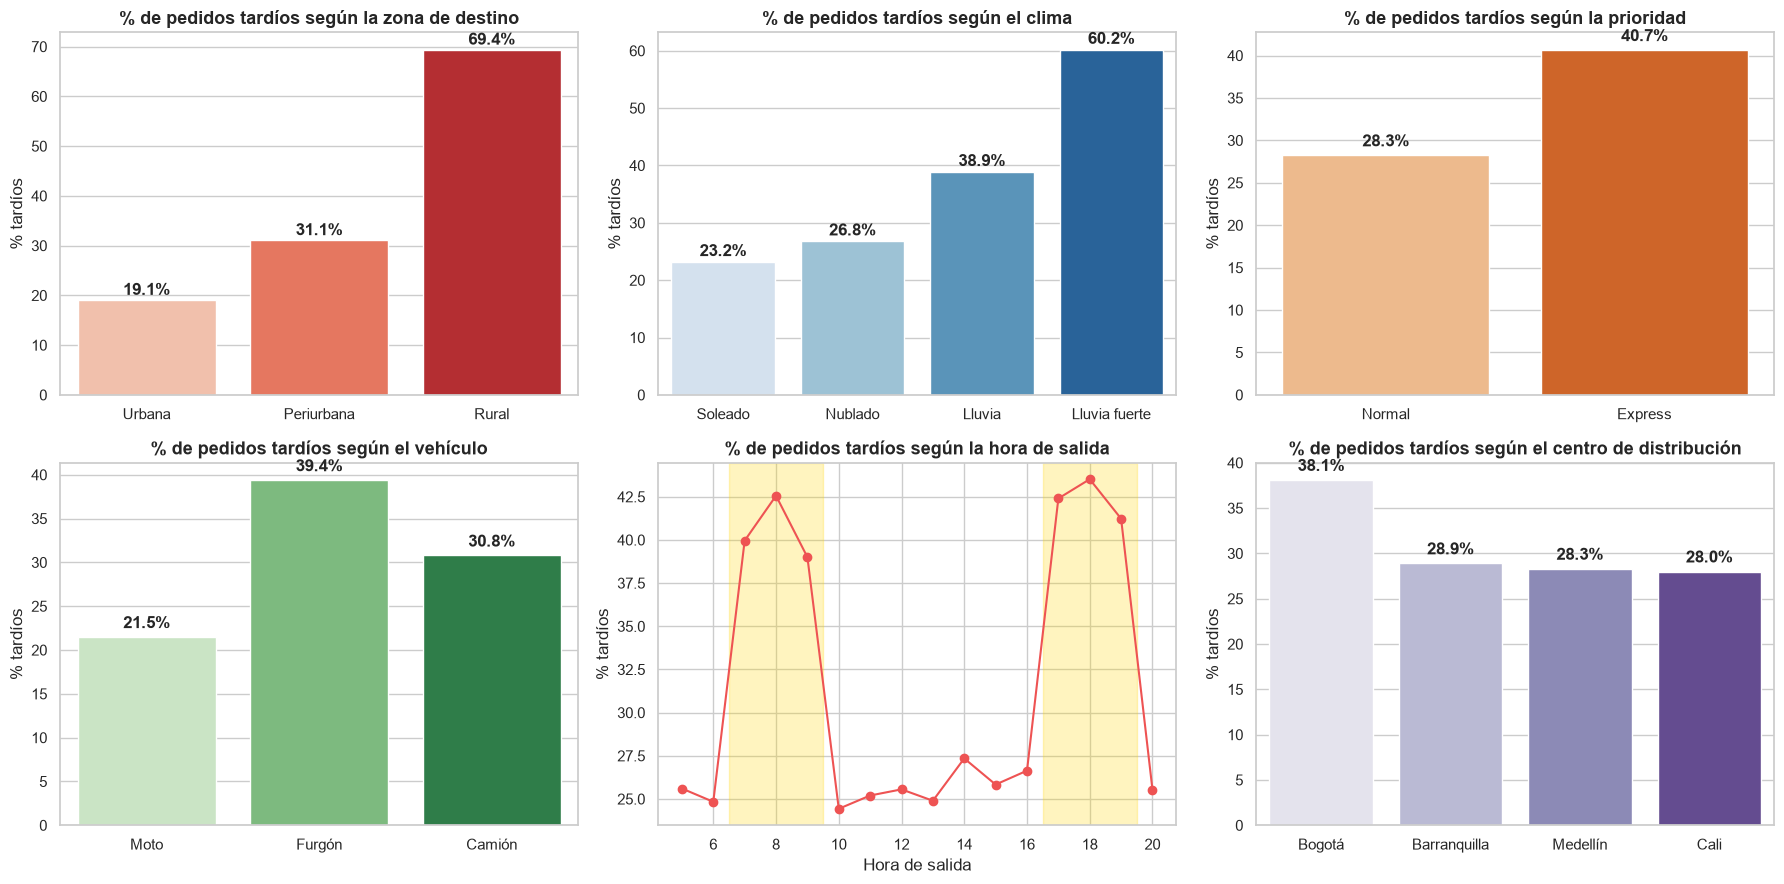

In [17]:
def tasa_tarde(col, orden=None):
    t = (df_limpio.groupby(col)["entrega_tardia_bin"].mean() * 100).round(1)
    return t.reindex(orden) if orden is not None else t.sort_values(ascending=False)

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()

# 1. Zona
t = tasa_tarde("zona_destino", ["Urbana", "Periurbana", "Rural"])
sns.barplot(x=t.index, y=t.values, ax=axes[0], palette="Reds", hue=t.index, legend=False)
axes[0].set_title("% de pedidos tardíos según la zona de destino")
axes[0].set_ylabel("% tardíos"); axes[0].set_xlabel("")
for i, v in enumerate(t.values): axes[0].text(i, v + 1, f"{v}%", ha="center", fontweight="bold")

# 2. Clima
t = tasa_tarde("clima", ["Soleado", "Nublado", "Lluvia", "Lluvia fuerte"])
sns.barplot(x=t.index, y=t.values, ax=axes[1], palette="Blues", hue=t.index, legend=False)
axes[1].set_title("% de pedidos tardíos según el clima")
axes[1].set_ylabel("% tardíos"); axes[1].set_xlabel("")
for i, v in enumerate(t.values): axes[1].text(i, v + 1, f"{v}%", ha="center", fontweight="bold")

# 3. Prioridad
t = tasa_tarde("prioridad", ["Normal", "Express"])
sns.barplot(x=t.index, y=t.values, ax=axes[2], palette="Oranges", hue=t.index, legend=False)
axes[2].set_title("% de pedidos tardíos según la prioridad")
axes[2].set_ylabel("% tardíos"); axes[2].set_xlabel("")
for i, v in enumerate(t.values): axes[2].text(i, v + 1, f"{v}%", ha="center", fontweight="bold")

# 4. Vehículo
t = tasa_tarde("tipo_vehiculo", ["Moto", "Furgón", "Camión"])
sns.barplot(x=t.index, y=t.values, ax=axes[3], palette="Greens", hue=t.index, legend=False)
axes[3].set_title("% de pedidos tardíos según el vehículo")
axes[3].set_ylabel("% tardíos"); axes[3].set_xlabel("")
for i, v in enumerate(t.values): axes[3].text(i, v + 1, f"{v}%", ha="center", fontweight="bold")

# 5. Hora de salida (no lineal)
t = (df_limpio.groupby("hora_salida")["entrega_tardia_bin"].mean() * 100)
axes[4].plot(t.index, t.values, marker="o", color="#EE5353")
axes[4].axvspan(6.5, 9.5, color="gold", alpha=0.25); axes[4].axvspan(16.5, 19.5, color="gold", alpha=0.25)
axes[4].set_title("% de pedidos tardíos según la hora de salida")
axes[4].set_xlabel("Hora de salida"); axes[4].set_ylabel("% tardíos")

# 6. Centro
t = tasa_tarde("centro_distribucion")
sns.barplot(x=t.index, y=t.values, ax=axes[5], palette="Purples", hue=t.index, legend=False)
axes[5].set_title("% de pedidos tardíos según el centro de distribución")
axes[5].set_ylabel("% tardíos"); axes[5].set_xlabel("")
for i, v in enumerate(t.values): axes[5].text(i, v + 1, f"{v}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

**Interpretación:**

1. **Zona de destino:** Es la variable con el efecto más fuerte. El 69,4 % de los pedidos rurales llegan tarde, contra un 31,1 % en periurbana y 19,1 % en urbana.

2. **Clima:** El riesgo crece con la intensidad de la lluvia.  Se tiene para soleado un 23,2 %,  nublado un 26,8 %,  lluvia un 38,9 % y para lluvia fuerte 60,2 %. La lluvia fuerte casi que duplica el riesgo base de pedido tardío.

3. **Prioridad:** Los pedidos Express llegan tarde el 40,7 % contra 28,3 % de los Normales. La ventana de entrega más corta (Express) deja menos margen.

4. **Vehículo:** El furgón es el más afectado (39,4 %), luego el camión (30,8 %) y la moto (21,5 %). 

5. **Hora de salida (relación NO lineal):** Los picos aparecen en 7–9 h y 17–19 h (≈ 40–44 % tardíos), mientras que el resto del día ronda el 25 %. Este el efecto de las horas pico, es decir la hora como número no sirve (7 y 17 son "altas", 12 es "baja"), por eso crearemos una variable hora_pico.

6. **Centro de distribución:** Bogotá destaca con 38,1%, frente a ≈ 28 % en los otros tres centros. Es importante revisar posteriormente si es por tráfico, por el tipo de rutas o por la operación.

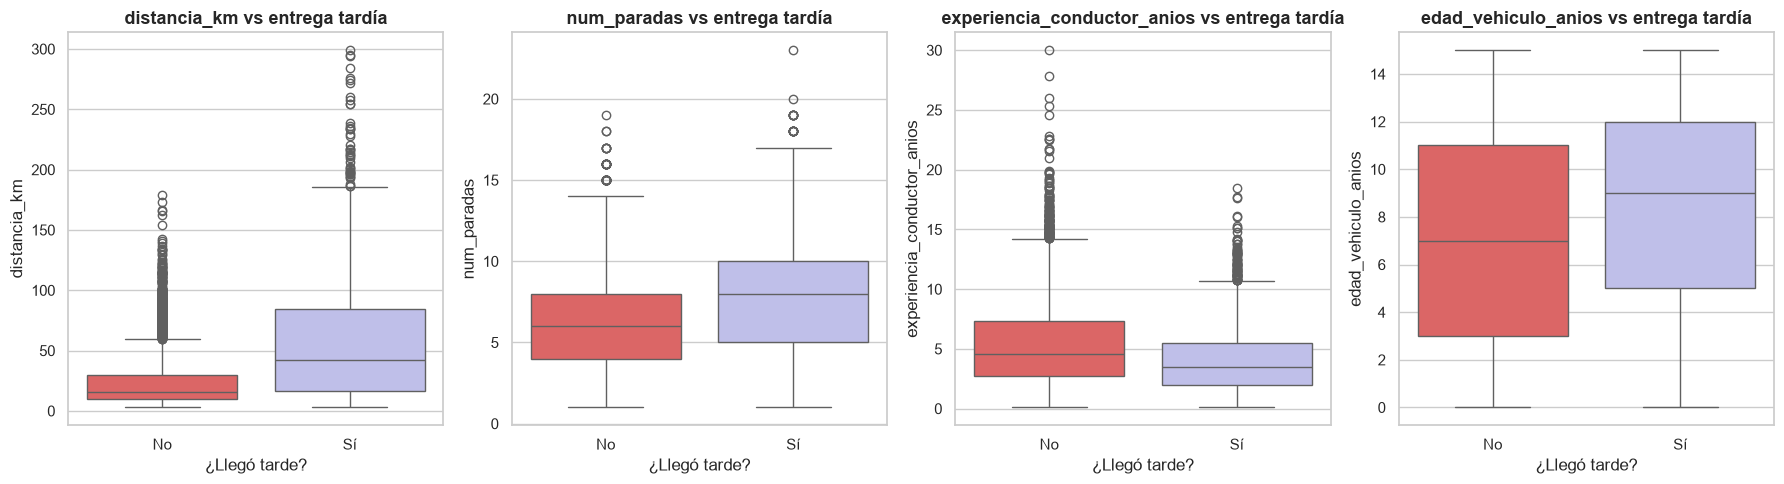

                distancia_km  num_paradas  experiencia_conductor_anios  \
entrega_tardia                                                           
No                      15.9          6.0                          4.6   
Sí                      41.8          8.0                          3.5   

                edad_vehiculo_anios  peso_kg  valor_pedido_COP  
entrega_tardia                                                  
No                              7.0    127.2          216000.0  
Sí                              9.0    173.7          214800.0  


In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, var in zip(axes, ["distancia_km", "num_paradas", "experiencia_conductor_anios", "edad_vehiculo_anios"]):
    sns.boxplot(data=df_limpio, x="entrega_tardia", y=var, order=["No", "Sí"], ax=ax,
                palette=["#B8B8F0", "#EE5353"], hue="entrega_tardia", legend=False)
    ax.set_title(f"{var} vs entrega tardía")
    ax.set_xlabel("¿Llegó tarde?")
plt.tight_layout()
plt.show()

print(df_limpio.groupby("entrega_tardia")[["distancia_km", "num_paradas", "experiencia_conductor_anios",
                                           "edad_vehiculo_anios", "peso_kg", "valor_pedido_COP"]].median().round(1))

**Interpretación (variables numéricas vs. objetivo):**
- **Distancia:** la mediana de los pedidos tardíos es muy superior a la de los puntuales, y la caja de los tardíos está desplazada hacia valores altos (el 75 % de los tardíos llega hasta 86 km, frente a 31 km en los puntuales).

- **Número de paradas:** los pedidos tardíos tienen mediana de 8 paradas frente a una de 6 en los puntuales. Basicamente más paradas, más oportunidades de retraso que se acumulan.

- **Experiencia del conductor:** los conductores con menos experiencia están más asociados a retrasos.

- **Edad del vehículo:** los vehículos más viejos se asocian levemente con más retrasos (mediana 8 vs 7 años).

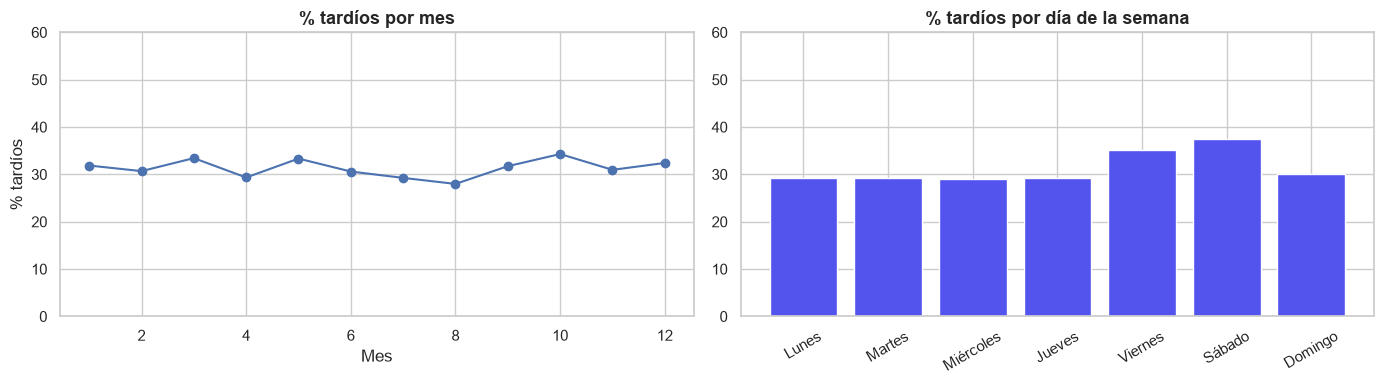

In [19]:
orden_dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
t = df_limpio.groupby("mes")["entrega_tardia_bin"].mean() * 100
axes[0].plot(t.index, t.values, marker="o"); axes[0].set_ylim(0, 60)
axes[0].set_title("% tardíos por mes"); axes[0].set_xlabel("Mes"); axes[0].set_ylabel("% tardíos")
t = (df_limpio.groupby("dia_semana")["entrega_tardia_bin"].mean() * 100).reindex(orden_dias)
axes[1].bar(t.index, t.values, color="#5353EE"); axes[1].set_ylim(0, 60)
axes[1].set_title("% tardíos por día de la semana"); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Interpretación:** El mes no muestra un patrón estacional claro (todos entre 28 % y 34 %). Por día de la semana sí hay diferencia, el viernes (≈34,8 %) y sábado (≈37,5 %)** superan al resto de días (≈ 29–30 %), posiblemente por mayor volumen o menor disponibilidad de personal en fines de semana.

### Matriz de correlación

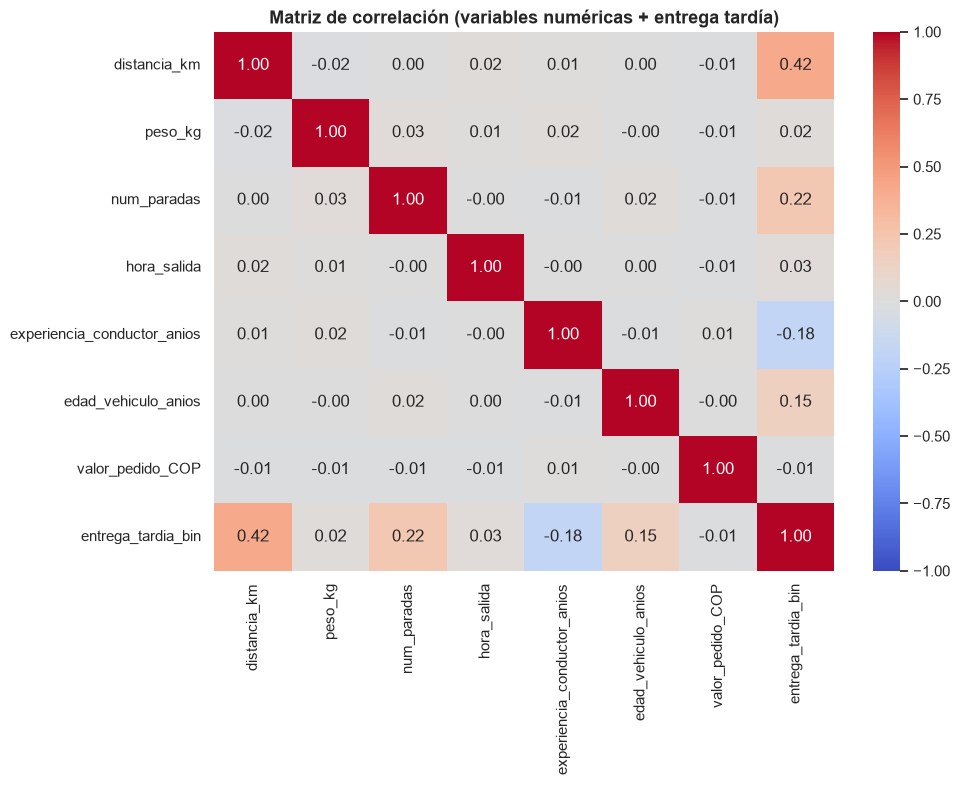

entrega_tardia_bin             1.00
distancia_km                   0.42
num_paradas                    0.22
edad_vehiculo_anios            0.15
hora_salida                    0.03
peso_kg                        0.02
valor_pedido_COP              -0.01
experiencia_conductor_anios   -0.18
Name: entrega_tardia_bin, dtype: float64


In [20]:
corr = df_limpio[vars_num + ["entrega_tardia_bin"]].corr().round(2)
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriz de correlación (variables numéricas + entrega tardía)")
plt.show()
print(corr["entrega_tardia_bin"].sort_values(ascending=False))

**Interpretación:**
- Con el objetivo, la correlación más alta es distancia_km (+0,42); luego num_paradas (+0,22), experiencia_conductor_anios (-0,18, a más experiencia, menos retrasos) y edad_vehiculo_anios (+0,15).

- hora_salida (+0,03) casi no se correlaciona, pero ya vimos en la gráfica que sí importa. La correlación de Pearson solo mide relaciones lineales y aquí el efecto es de "horas pico".
- peso_kg y valor_pedido_COP tienen correlación ≈ 0 con el objetivo. Por sí solas aportan poco.
- Entre las variables de entrada las correlaciones son prácticamente nulas (≈ 0), así que no hay multicolinealidad que preocupe.


---
## 3.4 Tratamiento de nulos (estrategia por columna)
Primero verificamos de qué depende cada variable, para imputar con el grupo correcto:

In [21]:
print("Paradas - mediana por zona   :", df_limpio.groupby("zona_destino")["num_paradas"].median().to_dict())
print("Paradas - mediana por vehículo:", df_limpio.groupby("tipo_vehiculo")["num_paradas"].median().to_dict())
print("Edad veh - mediana por vehículo:", df_limpio.groupby("tipo_vehiculo")["edad_vehiculo_anios"].median().to_dict())
print("Experiencia - mediana por vehículo:", df_limpio.groupby("tipo_vehiculo")["experiencia_conductor_anios"].median().to_dict())
print("Valor - mediana por tipo_cliente:", df_limpio.groupby("tipo_cliente")["valor_pedido_COP"].median().to_dict())
print("Valor - mediana por prioridad:", df_limpio.groupby("prioridad")["valor_pedido_COP"].median().to_dict())

Paradas - mediana por zona   : {'Periurbana': 6.0, 'Rural': 6.0, 'Urbana': 6.0}
Paradas - mediana por vehículo: {'Camión': 6.0, 'Furgón': 9.0, 'Moto': 4.0}
Edad veh - mediana por vehículo: {'Camión': 7.0, 'Furgón': 7.5, 'Moto': 7.0}
Experiencia - mediana por vehículo: {'Camión': 4.35, 'Furgón': 4.2, 'Moto': 4.1}
Valor - mediana por tipo_cliente: {'Empresa': 209000.0, 'Hogar': 216000.0, 'Tienda': 222600.0}
Valor - mediana por prioridad: {'Express': 216900.0, 'Normal': 215800.0}


| Columna | Nulos | Estrategia | Justificación |
|---|---|---|---|
| hora_salida | 4 % + 10 inválidas | Eliminar filas | Al despachar la hora siempre se conoce; un nulo es un error de captura. Es una variable clave (horas pico) sin un buen sustituto, y perdemos solo ~4 % de las filas. Imputarla con 12 h asignaría "no pico" a pedidos que quizá sí lo eran. |
| distancia_km | 5 % | Mediana por zona | La zona afecta la distancia recorrida. No se debe asumir la mediana global, de apenas 19km, como una distancia representativa de todas las zonas de distribución cuando, por ejemplo, las zonas rurales tienen una propia de 86km. |
| peso_kg | 8 % + 15 ceros | Mediana por vehículo | Como para la variable ´distancia_km´, una mediana de vehículos con pesos tan distintos no sería representativa globalmente. |
| num_paradas | 6 % + 59 ceros | Mediana por vehículo | Varía por vehículo (moto 4, camión 6, furgón 9) pero no por zona (todas 6): por eso se agrupa por vehículo. |
| experiencia_conductor_anios | 11 % | Mediana global | Esta variable tiene una asimetría hacia la derecha, es decir hay pocos conductores con más años de experiencia. Esto conlleva a que si se hace un promedio, se arrastré el valor hacia arriba por estos pocos. Se aplica la mediana global, pues no depende del vehículo. |
| edad_vehiculo_anios | 7 % | Mediana global | Casi no varía por vehículo (7–7,5 años). |
| valor_pedido_COP | 5 % | Mediana global | Muy sesgada (media 301 mil vs mediana 216 mil) y no varía por tipo de cliente ni prioridad. La media estaría inflada por los pedidos grandes. |
| clima | 9 % | Categoría "No registrado" | Datos faltantes de una categoría tan variable como el clima no deben ser imputados por la moda, optamos por dejarlos sin registrar, y que así no afecten el procedimiento. |
| tipo_cliente | 3 % | Categoría "No registrado" | Es la misma justificación que con el  clima. |

In [22]:
print("Nulos antes de imputar:")
print(df_limpio.isna().sum()[df_limpio.isna().sum() > 0])

# 1) hora_salida: se eliminan las filas (siempre se conoce al despachar, es clave y no tiene proxy)
antes = len(df_limpio)
df_limpio = df_limpio.dropna(subset=["hora_salida"]).copy()
print(f"\nFilas eliminadas por hora_salida nula: {antes - len(df_limpio)}")

# 2) Numéricas: mediana por grupo (el grupo explica la variable)
df_limpio["distancia_km"] = df_limpio["distancia_km"].fillna(df_limpio.groupby("zona_destino")["distancia_km"].transform("median"))
df_limpio["peso_kg"] = df_limpio["peso_kg"].fillna(df_limpio.groupby("tipo_vehiculo")["peso_kg"].transform("median"))
df_limpio["num_paradas"] = df_limpio["num_paradas"].fillna(df_limpio.groupby("tipo_vehiculo")["num_paradas"].transform("median"))
df_limpio["edad_vehiculo_anios"] = df_limpio["edad_vehiculo_anios"].fillna(df_limpio["edad_vehiculo_anios"].median())

# 3) Numéricas sin grupo claro: mediana global (distribuciones sesgadas)
df_limpio["experiencia_conductor_anios"] = df_limpio["experiencia_conductor_anios"].fillna(df_limpio["experiencia_conductor_anios"].median())
df_limpio["valor_pedido_COP"] = df_limpio["valor_pedido_COP"].fillna(df_limpio["valor_pedido_COP"].median())

# 4) Categóricas: categoría explícita
df_limpio["clima"] = df_limpio["clima"].fillna("No registrado")
df_limpio["tipo_cliente"] = df_limpio["tipo_cliente"].fillna("No registrado")

print("\nNulos después de imputar:", df_limpio.isna().sum().sum())

Nulos antes de imputar:
distancia_km                   400
peso_kg                        655
num_paradas                    539
hora_salida                    330
clima                          720
experiencia_conductor_anios    880
edad_vehiculo_anios            560
tipo_cliente                   240
valor_pedido_COP               400
dtype: int64

Filas eliminadas por hora_salida nula: 330

Nulos después de imputar: 0


## 3.5 Ingeniería de variables: hora_pico
El EDA mostró que el efecto de la hora *no es lineal. Un modelo lineal (regresión logística) no puede capturar "alto en 7–9 y 17–19, bajo en 10–16" con la hora como número, por tanto vamos a crear una variable binaria que lo resume:

In [23]:
df_limpio["hora_salida"] = df_limpio["hora_salida"].astype(int)
df_limpio["hora_pico"] = df_limpio["hora_salida"].isin([7, 8, 9, 17, 18, 19]).astype(int)
print(df_limpio.groupby("hora_pico")["entrega_tardia_bin"].mean().round(3))

hora_pico
0    0.256
1    0.415
Name: entrega_tardia_bin, dtype: float64


**Resultado:** salir en hora pico se asocia con **41,5 %** de retrasos vs **25,6 %** fuera de pico.

## 3.6 Validación final y guardado de la base limpia

In [ ]:
print("Dimensiones finales:", df_limpio.shape)
print("Duplicados:", df_limpio.duplicated().sum())
print("Nulos totales:", df_limpio.isna().sum().sum())
print("Distancias <= 0:", (df_limpio["distancia_km"] <= 0).sum(), "| Pesos <= 0:", (df_limpio["peso_kg"] <= 0).sum(),
      "| Paradas < 1:", (df_limpio["num_paradas"] < 1).sum(), "| Horas fuera de rango:", (~df_limpio["hora_salida"].between(0, 23)).sum())
df_limpio.to_csv("logistica_entregas_limpio.csv", index=False)
print("Base limpia guardada")

Dimensiones finales: (7670, 20)
Duplicados: 0
Nulos totales: 0
Distancias <= 0: 0 | Pesos <= 0: 0 | Paradas < 1: 0 | Horas fuera de rango: 0
 Base limpia guardada


## 3.7 Codificación, división y escalado
- **Codificación:** get_dummies para las categóricas, pues los modelos solo entienden números. Además, se descartan id_pedido,fecha_despacho y el objetivo.
- **División 70 / 30:** con stratify=y y random_state=42.
- **Escalado:** con StandardScaler, ajustado solo con el conjunto de entrenamiento, para no filtrar información del test. Lo necesita la regresión logística; el árbol no lo requiere y usará los datos sin escalar.

Todas las variables de entrada están disponibles en el momento del despacho, así que el modelo no usa información del futuro.

In [26]:
X = df_limpio.drop(columns=["id_pedido", "fecha_despacho", "entrega_tardia", "entrega_tardia_bin"])
X = pd.get_dummies(X, columns=["dia_semana", "centro_distribucion", "zona_destino", "tipo_vehiculo",
                               "clima", "tipo_cliente", "prioridad"], dtype=int)
y = df_limpio["entrega_tardia_bin"]
print("X:", X.shape, "| y:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
print("Train:", X_train.shape, "% tardíos:", round(y_train.mean() * 100, 1))
print("Test :", X_test.shape, "% tardíos:", round(y_test.mean() * 100, 1))

X: (7670, 37) | y: (7670,)
Train: (5369, 37) % tardíos: 31.4
Test : (2301, 37) % tardíos: 31.4


In [27]:
escalador = StandardScaler()
X_train_esc = pd.DataFrame(escalador.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_esc = pd.DataFrame(escalador.transform(X_test), columns=X.columns, index=X_test.index)

---
# Fase 4: Modelado

Entrenamos dos modelos de clasificación: un árbol de decisión y una regresión logística. Para cada uno probamos varias configuraciones de hiperparámetros.

**¿Cómo elegimos la configuración sin mirar el test?**

Utilizamos el conjunto de entrenamiento para elegir la mejor configuración mediante validación cruzada de 5 particiones (CV), comparando el F1 de la clase "tarde". El conjunto de prueba se mantiene separado y se utiliza exclusivamente para evaluar el desempeño final del modelo.

## 4.1 Modelo A : Árbol de decisión
Hiperparámetros: max_depth (3, 5, 8, 12, sin límite) y `class_weight` (ninguno o `balanced`).

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
filas = []
for prof in [3, 5, 8, 12, None]:
    for cw in [None, "balanced"]:
        m = DecisionTreeClassifier(max_depth=prof, class_weight=cw, random_state=42)
        cv_f1 = cross_val_score(m, X_train, y_train, cv=cv, scoring="f1").mean()
        m.fit(X_train, y_train)
        filas.append({"max_depth": prof if prof else "Sin límite", "class_weight": cw if cw else "Ninguno",
                      "F1 (CV, train)": round(cv_f1, 4),
                      "Acc train": round(m.score(X_train, y_train), 3),
                      "Acc test": round(m.score(X_test, y_test), 3)})
tabla_arbol = pd.DataFrame(filas)
tabla_arbol

,max_depth,class_weight,"F1 (CV, train)",Acc train,Acc test
0,3,Ninguno,0.5323,0.774,0.763
1,3,balanced,0.6157,0.730,0.711
2,5,Ninguno,0.5877,0.801,0.761
3,5,balanced,0.6189,0.784,0.759
4,8,Ninguno,0.5912,0.852,0.774
5,8,balanced,0.6167,0.833,0.750
6,12,Ninguno,0.5814,0.937,0.752
7,12,balanced,0.5713,0.936,0.714
8,Sin límite,Ninguno,0.5687,1.000,0.722
9,Sin límite,balanced,0.5572,1.000,0.716


**Interpretación:**
- Sobreajuste: sin límite de profundidad el árbol obtiene accuracy 1,00 en entrenamiento y solo 0,72 en prueba, esto significa que memorizó los datos. A medida que se limita la profundidad la brecha se cierra.
- El class_weight="balanced" mejora el F1 en los árboles poco profundos (profundidad 3, 5 y 8), es decir el árbol deja de ignorar la clase "tarde". En los árboles muy profundos ya no ayuda, porque el problema allí es el sobreajuste.
- La mejor configuración por F1 en validación cruzada es "max_depth=5 + class_weight="balanced" (F1 CV ≈ 0,619).  Es lo bastante profunda para captar patrones y lo bastante corta para generalizar y poder ser explicada.

## 4.2 Modelo B: Regresión logística
Escalamos las variables para facilitar el aprendizaje, usamos el hiperparámetro C para controlar la complejidad del modelo (evitar que el modelo se ajuste demasiado a los datos de entrenamiento) y class_weight para manejar el desbalance entre clases.

- C pequeño: el modelo evita aprender demasiados detalles de los datos.
- C grande: el modelo tiene más libertad para aprender patrones y detalles de los datos.


In [31]:
filas = []
for C in [0.01, 0.1, 1, 10]:
    for cw in [None, "balanced"]:
        m = LogisticRegression(C=C, class_weight=cw, max_iter=2000)
        cv_f1 = cross_val_score(m, X_train_esc, y_train, cv=cv, scoring="f1").mean()
        m.fit(X_train_esc, y_train)
        filas.append({"C": C, "class_weight": cw if cw else "Ninguno",
                      "F1 (CV, train)": round(cv_f1, 4),
                      "Acc train": round(m.score(X_train_esc, y_train), 3),
                      "Acc test": round(m.score(X_test_esc, y_test), 3)})
tabla_log = pd.DataFrame(filas)
tabla_log

,C,class_weight,"F1 (CV, train)",Acc train,Acc test
0,0.01,Ninguno,0.6796,0.827,0.837
1,0.01,balanced,0.7120,0.804,0.797
2,0.10,Ninguno,0.6895,0.827,0.840
3,0.10,balanced,0.7148,0.807,0.793
4,1.00,Ninguno,0.6908,0.827,0.840
5,1.00,balanced,0.7140,0.808,0.793
6,10.00,Ninguno,0.6906,0.828,0.840
7,10.00,balanced,0.7145,0.808,0.793


**Interpretación:**
- El valor de C casi no cambia el resultado de F1 ( entre 0,712 y 0,715 con "balanced"). El modelo es estable y con 37 variables y  aprox 5.400 filas no hay riesgo grande de sobreajuste.
- class_weight="balanced" sube el F1 en CV de ≈ 0,69 a ≈ 0,71. Sin balancear, el modelo tiene mayor accuracy (0,84) pero lo logra "jugando seguro" a favor de la clase mayoritaria. 
- Elegimos la combinación con mejor F1. Esta fue C = 0,1 con class_weight="balanced" (aunque la diferencia con los otros valores de C es mínima).

In [32]:
mejor_a = tabla_arbol.sort_values("F1 (CV, train)", ascending=False).iloc[0]
mejor_l = tabla_log.sort_values("F1 (CV, train)", ascending=False).iloc[0]
print("Mejor árbol    :", mejor_a.to_dict())
print("Mejor logística:", mejor_l.to_dict())
prof_final = None if mejor_a["max_depth"] == "Sin límite" else int(mejor_a["max_depth"])
cw_a = None if mejor_a["class_weight"] == "Ninguno" else "balanced"
cw_l = None if mejor_l["class_weight"] == "Ninguno" else "balanced"
arbol = DecisionTreeClassifier(max_depth=prof_final, class_weight=cw_a, random_state=42).fit(X_train, y_train)
logistica = LogisticRegression(C=float(mejor_l["C"]), class_weight=cw_l, max_iter=2000).fit(X_train_esc, y_train)

Mejor árbol    : {'max_depth': 5, 'class_weight': 'balanced', 'F1 (CV, train)': 0.6189, 'Acc train': 0.784, 'Acc test': 0.759}
Mejor logística: {'C': 0.1, 'class_weight': 'balanced', 'F1 (CV, train)': 0.7148, 'Acc train': 0.807, 'Acc test': 0.793}


## 4.3 Interpretación de los modelos

### Árbol de decisión (primeros niveles)

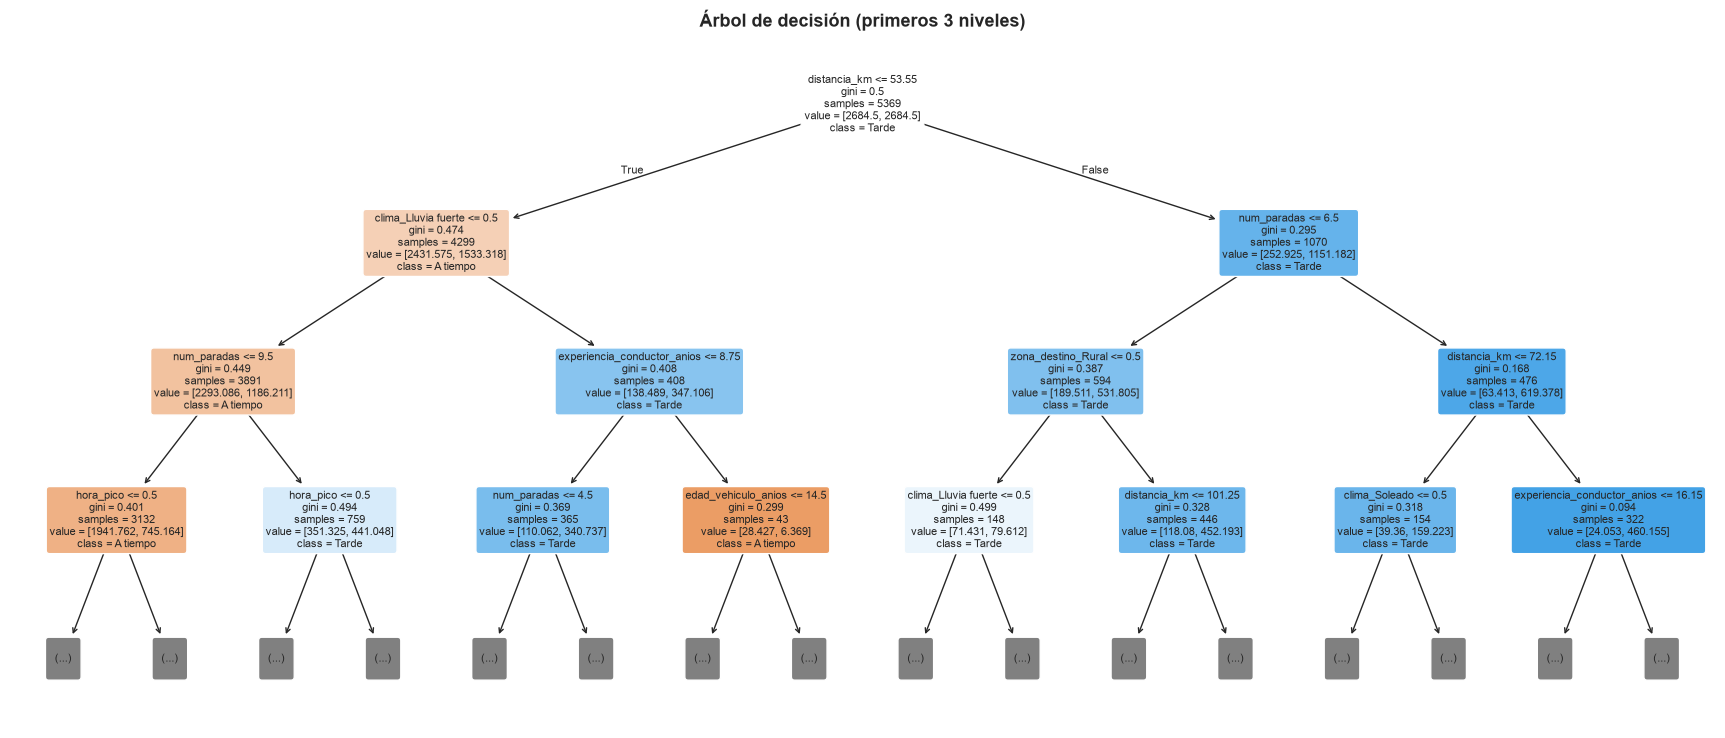

In [34]:
plt.figure(figsize=(22, 9))
plot_tree(arbol, feature_names=X.columns, class_names=["A tiempo", "Tarde"], filled=True, rounded=True,
          fontsize=8, max_depth=3)
plt.title("Árbol de decisión (primeros 3 niveles)")
plt.show()



Interpretación de las primeras divisiones:

El árbol pregunta primero si **distancia_km ≤ 53,5**:
- **Rama de distancias cortas (≤ 53,5 km):** lo siguiente que le importa es si hay lluvia fuerte y, luego, el número de paradas (corte en 9,5) o la experiencia** del conductor (corte en 8,75 años).
- **Rama de distancias largas (> 53,5 km):** mira el número de paradas (corte en 6,5) y si la zona es rural.

El arbol prioriza las variables: distancia, paradas, hora pico, lluvia fuerte y experiencia del conductor.

### Regresión logística (coeficientes sobre variables escaladas)
Un coeficiente **positivo** aumenta la probabilidad de entrega tardía y uno **negativo** la disminuye (por cada desviación estándar de la variable, manteniendo lo demás constante).

In [35]:
coef = pd.Series(logistica.coef_[0], index=X.columns).sort_values()
print(coef.round(3).tail(10)); print(coef.round(3).head(6))

dia_semana_Sábado             0.126
clima_Lluvia                  0.171
prioridad_Express             0.182
centro_distribucion_Bogotá    0.229
zona_destino_Rural            0.232
edad_vehiculo_anios           0.563
clima_Lluvia fuerte           0.577
num_paradas                   0.614
hora_pico                     0.633
distancia_km                  1.144
dtype: float64
experiencia_conductor_anios   -0.706
clima_Soleado                 -0.316
tipo_vehiculo_Moto            -0.196
clima_Nublado                 -0.188
prioridad_Normal              -0.182
centro_distribucion_Cali      -0.108
dtype: float64


**Interpretación:**
- **Aumentan el riesgo:** distancia_km (+1,14, el mayor), hora_pico (+0,63), num_paradas (+0,61), clima_Lluvia fuerte (0,58), edad_vehiculo_anios (+0,56), centro_distribucion_Bogotá (+0,23), zona_destino_Rural (+0,23) y prioridad_Express (+0,18).


- **Disminuyen el riesgo:** experiencia_conductor_anios (-0,71), clima_Soleado (-0,32), tipo_vehiculo_Moto (-0,20).

- zona_destino_Rural tiene un coeficiente modesto porque la distancia ya captura gran parte del efecto rural; el modelo solo agrega lo que la zona aporta además de la distancia.

- Ambos modelos coinciden en el ranking: **distancia, paradas, hora pico, lluvia fuerte y experiencia**.

---
# Fase 5: Evaluación

Evaluamos ambos modelos sobre el conjunto de prueba (30 %, que ningún modelo vio), tomando "tarde" como clase positiva.

## 5.1 Matrices de confusión

In [37]:
def evaluar(modelo, Xtr, Xte, nombre):
    out = {"Modelo": nombre}
    for etiqueta, Xs, ys in [("train", Xtr, y_train), ("test", Xte, y_test)]:
        p = modelo.predict(Xs)
        out[f"Accuracy {etiqueta}"] = accuracy_score(ys, p)
        out[f"Precision {etiqueta}"] = precision_score(ys, p)
        out[f"Recall {etiqueta}"] = recall_score(ys, p)
        out[f"F1 {etiqueta}"] = f1_score(ys, p)
    return out

tabla = pd.DataFrame([evaluar(arbol, X_train, X_test, "Árbol de decisión"),
                      evaluar(logistica, X_train_esc, X_test_esc, "Regresión logística")]).set_index("Modelo").round(3)
print(tabla.T)

pred_arbol = arbol.predict(X_test)
pred_log = logistica.predict(X_test_esc)
for nombre, p in [("Árbol", pred_arbol), ("Logística", pred_log)]:
    print(nombre); print(confusion_matrix(y_test, p)); print(classification_report(y_test, p, target_names=["A tiempo", "Tarde"]))

Modelo           Árbol de decisión  Regresión logística
Accuracy train               0.784                0.807
Precision train              0.654                0.661
Recall train                 0.661                0.791
F1 train                     0.657                0.720
Accuracy test                0.759                0.793
Precision test               0.615                0.635
Recall test                  0.624                0.801
F1 test                      0.620                0.708
Árbol
[[1296  282]
 [ 272  451]]
              precision    recall  f1-score   support

    A tiempo       0.83      0.82      0.82      1578
       Tarde       0.62      0.62      0.62       723

    accuracy                           0.76      2301
   macro avg       0.72      0.72      0.72      2301
weighted avg       0.76      0.76      0.76      2301

Logística
[[1245  333]
 [ 144  579]]
              precision    recall  f1-score   support

    A tiempo       0.90      0.79      0.84 

Gráficas de las matrices de confusión:

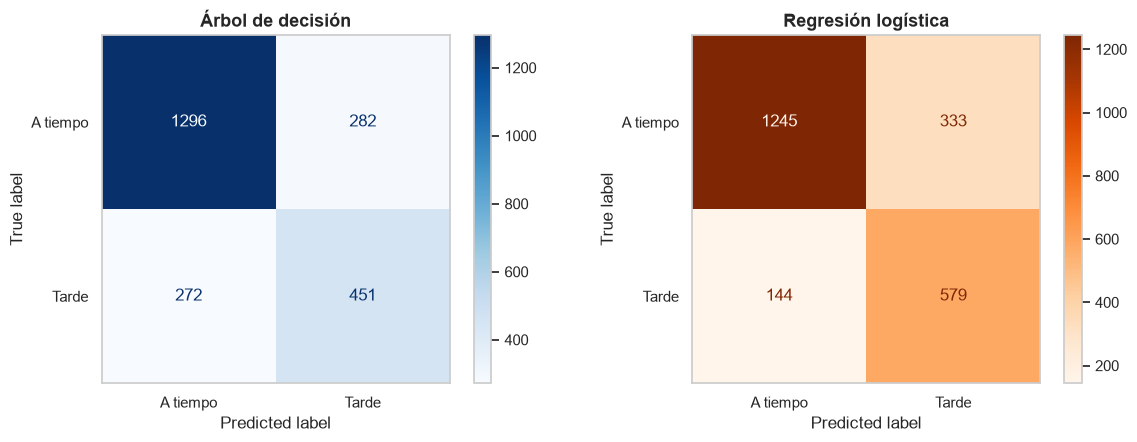

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_arbol, display_labels=["A tiempo", "Tarde"],
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Árbol de decisión"); axes[0].grid(False)
ConfusionMatrixDisplay.from_predictions(y_test, pred_log, display_labels=["A tiempo", "Tarde"],
                                        cmap="Oranges", ax=axes[1])
axes[1].set_title("Regresión logística"); axes[1].grid(False)
plt.tight_layout()
plt.show()

**En ambos modelos, de 2.301 pedidos, 723 llegaron tarde.**

| | Árbol | Regresión logística |
|---|---|---|
| Tardíos detectados (VP) | 451 | 579 |
| Tardíos NO detectados (FN) | 272 | 144 |
| Falsas alarmas (FP) | 282 | 333 |
| A tiempo bien clasificados (VN) | 1.296 | 1.245 |

La regresión logística reduce los falsos negativos casi a la mitad (144 vs 272) a cambio de 51 falsas alarmas más.

## 5.2 Tabla comparativa y chequeo de sobreajuste (train vs test)


| Métrica | Árbol train | Árbol test | Logística train | Logística test |
|---|---|---|---|---|
| Accuracy | 0,784 | 0,759 | 0,807 | 0,793 |
| Precision | 0,654 | 0,615 | 0,661 | 0,635 |
| **Recall** | 0,661 | 0,624 | 0,791 | 0,801 |
| **F1** | 0,657 | 0,620 | 0,720 | 0,708 |

**Sobreajuste:**
- **Árbol:** En acurracy hay una brecha de 2,5 puntos porcentuales. El árbol funciona un poco mejor con los datos que utilizó para aprender que con datos nuevos, pero la diferencia es pequeña, por eso no presenta un sobreajuste importante.
- **Regresión logística:** train y test son prácticamente iguales (F1 0,720 vs 0,708, recall 0,791 vs 0,801). No hay sobreajuste.

## 5.3 Elección del mejor modelo para el negocio
Elegimos la **regresión logística**:

1. **Recall = 0,80 vs 0,62:** detecta 8 de cada 10 pedidos que llegarán tarde. En la Fase 1 argumentamos que el falso negativo es el error más costoso, y aquí es donde la diferencia es mayor.
2. **Mejor F1** (0,71 vs 0,62) y mejor precision (0,64 vs 0,62): no solo detecta más, también acierta más al marcar.
3. **Generaliza mejor**: no muestra sobreajuste.
4. **Entrega una probabilidad**, no solo un sí/no. La gerencia puede crear un "semáforo de riesgo" y elegir el umbral según su capacidad de reacción (esto se explicara mejor posteriormente).



### Ajuste del umbral de decisión (aporte al negocio)
Por defecto el modelo marca "tarde" si la probabilidad es ≥ 0,5. Si la gerencia tiene capacidad para intervenir más pedidos, puede bajar el umbral y ganar recall a costa de precision:

In [40]:
prob = logistica.predict_proba(X_test_esc)[:, 1]
filas = []
for u in [0.3, 0.4, 0.5, 0.6]:
    p = (prob >= u).astype(int)
    filas.append({"umbral": u, "precision": precision_score(y_test, p), "recall": recall_score(y_test, p),
                  "F1": f1_score(y_test, p), "pedidos marcados %": p.mean() * 100})
print(pd.DataFrame(filas).round(3))

   umbral  precision  recall     F1  pedidos marcados %
0     0.3      0.519   0.916  0.663              55.411
1     0.4      0.581   0.873  0.698              47.197
2     0.5      0.635   0.801  0.708              39.635
3     0.6      0.715   0.736  0.725              32.334


**Interpretación:** Con umbral 0,5 se detecta el 80 % de los retrasos marcando ≈ 40 % de los pedidos. Bajando a 0,4 se detecta el 87 % marcando ≈ 47 %; con 0,3 se llega al 92 %, pero habría que intervenir más de la mitad de los pedidos (precision ≈ 52 %, casi la mitad serían falsas alarmas). El umbral correcto depende del costo de intervenir frente al costo de un retraso, un dato que solo tiene la gerencia.

---
# Fase 6: Recomendaciones

### ¿Qué variables parecen más relacionadas con el retraso?
Según el EDA y los dos modelos (que coinciden): (1) distancia / zona rural, (2) número de paradas, (3) salir en hora pico, (4) lluvia fuerte, (5) poca experiencia del conductor, y en menor medida la edad del vehículo, la prioridad Express y el centro de Bogotá. El peso del pedido, su valor y el tipo de cliente casi no aportan.

### Recomendaciones accionables para la gerencia de operaciones

1. **Usar el modelo como semáforo en el despacho:** Calcular la probabilidad de retraso de cada pedido al despachar y activar un protocolo (reasignar conductor, avisar al cliente, ajustar ruta) cuando supere un umbral (se sugiere empezar con 0,4: detecta ≈ 87 % de los retrasos).

2. **Ajustar los tiempos de entrega en rutas rurales y largas:** Establecer tiempos de entrega más realistas para estas zonas y evaluar la viabilidad de crear centros de acopio intermedios, ya que los pedidos rurales presentan una tasa de retraso cercana al 70 %.

3. **Evitar o reprogramar salidas en hora pico (7–9 h y 17–19 h), sobre todo en Express y en rutas largas:** El riesgo sube de 26 % a 41 %, y para pedidos Express en pico llega a ≈ 54 %. Adelantar la salida de las rutas largas a antes de las 7 h o después de las 9 h.

4. **Limitar el número de paradas por ruta:** Especialmente en furgones (mediana de 9 paradas y 40 % de retrasos). Rebalancear cargas para que las rutas con muchas paradas se repartan en más vehículos.

5. **Asignar los conductores más experimentados a las rutas de mayor riesgo:** Asignar conductores experimentados a las rutas de mayor riesgo. Priorizar su asignación en recorridos rurales, largos o con condiciones climáticas difíciles, y fortalecer la capacitación de los conductores nuevos.

6. **Plan de contingencia para lluvia fuerte:** Incorporar el pronóstico climático a la programación del día y añadir un margen de tiempo adicional; con lluvia fuerte el 61 % de los pedidos llega tarde.





### Limitaciones de este análisis

- **Disponibilidad de datos limitada**: Solo se disponía de información correspondiente al año 2025, lo que limita la capacidad de identificar patrones de comportamiento a largo plazo y evaluar si los resultados se mantienen en diferentes épocas del año.

- **Ausencia de variables relevantes**: No se contaba con información sobre factores importantes como la densidad del tráfico, los accidentes o incidentes en ruta, entre otros. Estas variables podrían ayudar a explicar mejor los retrasos y mejorar la capacidad predictiva del modelo.

- **Falta de información sobre las ventanas de entrega**: Era fundamental conocer la ventana exacta de entrega prometida por la empresa a cada cliente. Sin esta información, la identificación de un retraso puede no reflejar completamente el compromiso real de entrega, lo que limita la precisión del análisis.

- **Ausencia de una evaluación económica de los errores**: No se modeló el costo económico de los falsos negativos, es decir, de los pedidos que realmente llegan tarde, pero que el modelo clasifica como entregas a tiempo. Cuantificar este costo permitiría a la gerencia evaluar el impacto de estos errores y tomar mejores decisiones al implementar el modelo.


---
# Declaración de uso de Inteligencia Artificial
Para el desarrollo de este proyecto se utilizó inteligencia artificial generativa, específicamente Claude y ChatGPT, como herramientas de apoyo en la elaboración de la mayoría de los códigos implementados. La estrategia consistió en tomar como punto de partida los códigos trabajados con la profesora Yasmin en las diferentes guías de clase y, a partir de ellos, apoyarnos en estas herramientas para adaptarlos a la nueva base de datos, ajustar las variables de interés y lograr que los procedimientos respondieran a los objetivos del proyecto. De esta manera, se buscó aprovechar los conocimientos y las herramientas adquiridas durante el curso, utilizando la inteligencia artificial como un apoyo para adaptar y complementar lo aprendido, y no como un reemplazo del proceso de aprendizaje.
